# Shopping event activity
Google Merchandise Store · November 2020

This notebook reads the aggregate BigQuery export from the public GA4 sample.
Each bar counts distinct `user_pseudo_id` values for one event. The display
follows the usual shopping order. The event populations are independent, so
the chart cannot establish a sequential funnel or measure step-to-step drop-off.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt

event_labels = {
    "view_item": "Viewed product",
    "add_to_cart": "Added to cart",
    "begin_checkout": "Began checkout",
    "purchase": "Purchased",
}

# Support running from the repository root or the notebook directory.
data_dir = Path("data")
if Path.cwd().name == "python":
    data_dir = Path("../data")
csv_path = data_dir / "funnel_events_nov2020.csv"
if not csv_path.is_file():
    raise FileNotFoundError(
        f"Missing {csv_path}. See data/README.md for the BigQuery export steps."
    )

Matplotlib is building the font cache; this may take a moment.


## Validate and order the input

The export should contain one nonnegative integer count for each shopping event.
Duplicate rows or missing values are flagged before plotting.

In [2]:
counts = {}
with csv_path.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)
    if reader.fieldnames != ["event_name", "users"]:
        raise ValueError("Expected the CSV header event_name,users.")

    for row in reader:
        event = (row["event_name"] or "").strip()
        raw_count = (row["users"] or "").strip()
        if None in row or not event or not raw_count:
            raise ValueError(f"Malformed or missing value on CSV line {reader.line_num}.")
        if event not in event_labels:
            raise ValueError(f"Unexpected event: {event!r}.")
        if event in counts:
            raise ValueError(f"Duplicate event: {event!r}.")
        if not raw_count.isascii() or not raw_count.isdecimal():
            raise ValueError(f"Expected a nonnegative integer count for {event!r}.")
        counts[event] = int(raw_count)

missing_events = event_labels.keys() - counts.keys()
if missing_events:
    raise ValueError(f"Missing events: {', '.join(sorted(missing_events))}.")

ordered_counts = [counts[event] for event in event_labels]
for event, count in zip(event_labels, ordered_counts):
    print(f"{event:<16} {count:>7,}")

view_item         21,440
add_to_cart        2,060
begin_checkout     4,219
purchase           1,532


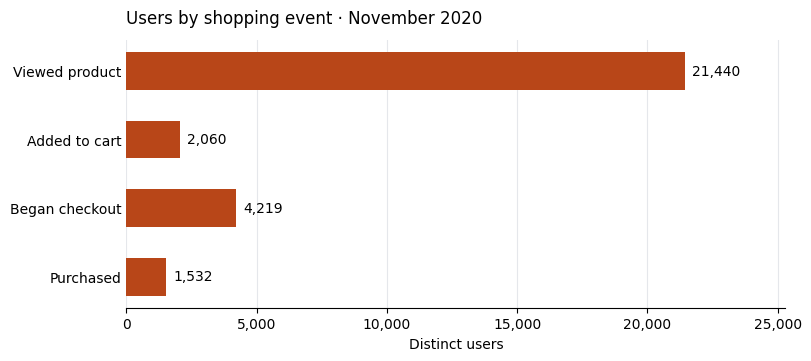

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
labels = list(event_labels.values())
bars = ax.barh(labels, ordered_counts, height=0.55, color="#B84618")
ax.bar_label(bars, labels=[f"{count:,}" for count in ordered_counts], padding=5)
ax.invert_yaxis()
ax.set_xlim(0, max(ordered_counts) * 1.18 or 1)
ax.set_title("Users by shopping event · November 2020", loc="left", pad=12)
ax.set_xlabel("Distinct users")
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E5E7EB")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.show()

More users recorded checkout than add-to-cart. Investigate event coverage and the ordering of events within sessions before defining a sequential funnel.